# CartPole DQN Target Networks Across Three Seeds

**Question:** Does a lagged target network stabilize this small DQN compared with updating against the online network?

Kerem Ozcan | IBM AI Engineering portfolio | Prepared with AI assistance

Original experiment code developed from course concepts. This notebook contains no IBM assessment solutions or supplied course model predictions.

## Design and evaluation boundary

CartPole-v1 with the same500-step limit and natural reward throughout. Compare online-target versus a target synchronized every500 environment steps. Match network, optimizer, replay capacity, warmup, exploration schedule and20,000 environment steps per training seed. Train seeds11/22/33; validation reset seeds1000-1004 choose checkpoints; only then evaluate greedy policies on20 reserved test seeds2000-2019 per training seed. End episodes on either termination or truncation, but bootstrap value targets on truncation. Show the random baseline, all per-seed results and standard deviation across training-seed means.

CartPole is a simple simulated task. Three training seeds and20 test episodes per seed are a bounded study, not general RL robustness or real-world control evidence. The online-target configuration may fail; retain that result.

## Runtime

Kaggle internet is required for provider-hosted inputs/models. Local verification uses already installed isolated environments. `SECOND_BATCH_FULL=0` selects a small local correctness pilot for the neural projects; the published Kaggle version uses the documented full experiment budget. Data and weights stay in scratch storage; only JSON evidence, plots and notebook outputs are exported.

In [1]:
import os
import sys
import subprocess
import gzip
import shutil
from pathlib import Path
os.environ["USE_TF"]="0"
os.environ["TOKENIZERS_PARALLELISM"]="false"
os.environ["OMP_NUM_THREADS"]="1"
ON_KAGGLE=Path("/kaggle/working").is_dir()
if ON_KAGGLE and True:
    subprocess.run([sys.executable,"-m","pip","install","-q",*['gymnasium==1.1.1']],check=True)
import matplotlib.pyplot as plt
import numpy as np
import json
FULL_RUN=os.environ.get("SECOND_BATCH_FULL","1")=="1"
LOCAL_ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/"provenance/source-manifest.json").exists()),Path.cwd())
WORK=Path("/kaggle/working") if ON_KAGGLE else LOCAL_ROOT/".lab-cache/second-batch-notebooks"/'cartpole'/"exports"
SCRATCH=Path("/kaggle/temp/ibm-second-batch") if ON_KAGGLE else LOCAL_ROOT/".lab-cache/second-batch-notebooks"/'cartpole'/"scratch"
WORK.mkdir(parents=True,exist_ok=True);SCRATCH.mkdir(parents=True,exist_ok=True)
DATA_ROOT=SCRATCH/"inputs" if ON_KAGGLE else LOCAL_ROOT/".lab-cache/second-batch-data"
RUN_OUTPUT=SCRATCH/'cartpole';OUTPUT=WORK/'cartpole';OUTPUT.mkdir(parents=True,exist_ok=True)


Matplotlib is building the font cache; this may take a moment.


## Inputs and provenance

[Farama Gymnasium CartPole](https://gymnasium.farama.org/environments/classic_control/cart_pole/) and its [time-limit guidance](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/). This is original experiment code prepared with AI assistance from the course's deep Q-learning concepts.

Provider downloads must match the pinned SHA-256 values below. Model weights are fetched from the original provider; no submitted lab checkpoint is reused.

In [2]:
"""Small, standalone data acquisition helpers embedded in the Kaggle releases."""

import hashlib
import shutil
import tarfile
import urllib.request
from pathlib import Path


def verified_download(url: str, target: Path, expected_sha256: str) -> Path:
    """Download to a temporary file and accept only the reviewed dataset bytes."""
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.is_file() and hashlib.sha256(target.read_bytes()).hexdigest() == expected_sha256:
        return target
    temporary = target.with_suffix(target.suffix + ".download")
    try:
        with urllib.request.urlopen(url, timeout=60) as response, temporary.open("wb") as stream:
            shutil.copyfileobj(response, stream)
        if hashlib.sha256(temporary.read_bytes()).hexdigest() != expected_sha256:
            raise ValueError("Downloaded data changed; review its provenance before running.")
        temporary.replace(target)
    finally:
        temporary.unlink(missing_ok=True)
    return target


def unpack_regular_tar(archive: Path, destination: Path) -> None:
    """Reject links, special files and traversal before writing any archive member."""
    root = destination.resolve()
    with tarfile.open(archive) as bundle:
        members = bundle.getmembers()
        for member in members:
            path = root / member.name
            if (
                Path(member.name).is_absolute()
                or not path.resolve().is_relative_to(root)
                or not (member.isfile() or member.isdir())
            ):
                raise ValueError("Unsafe dataset archive member.")
        for member in members:
            path = root / member.name
            if member.isdir():
                path.mkdir(parents=True, exist_ok=True)
            else:
                path.parent.mkdir(parents=True, exist_ok=True)
                with bundle.extractfile(member) as source, path.open("wb") as target:
                    shutil.copyfileobj(source, target)


In [3]:
INPUTS=[]
for entry in INPUTS:
    path=verified_download(entry["url"],DATA_ROOT/entry["file"],entry["sha256"])
    if path.suffix==".gz":
        with gzip.open(path,"rb") as source,path.with_suffix("").open("wb") as target:
            shutil.copyfileobj(source,target)


## Standalone implementation

Expand this cell to inspect data partitions, actual sample accounting, training and selected-checkpoint reload checks.

In [4]:
"""Shared provenance and evaluation helpers for the selected portfolio projects."""

from __future__ import annotations

import hashlib
import importlib.metadata
import json
import platform
import random
from collections import Counter, defaultdict
from datetime import UTC, datetime
from pathlib import Path


def file_sha256(path: Path) -> str:
    """Hash an input/checkpoint without reading the entire file into memory."""
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def write_json(path: Path, value: dict | list) -> None:
    """Publish a complete JSON artifact atomically."""
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8"
    )
    temporary.replace(path)


def runtime(packages: list[str]) -> dict:
    """Capture versions without collecting environment variables or host paths."""
    return {
        "utc": datetime.now(UTC).isoformat(),
        "python": platform.python_version(),
        "platform": platform.system(),
        "packages": {name: importlib.metadata.version(name) for name in packages},
    }


def source_identity(project_file: str | None, embedded_digest: str | None = None) -> dict:
    """Bind module runs and generated notebooks to their authored source files."""
    project_digest = file_sha256(Path(project_file)) if project_file else embedded_digest
    common_digest = (
        file_sha256(Path(__file__))
        if "__file__" in globals()
        else globals().get("COMMON_SOURCE_SHA256")
    )
    if not project_digest or not common_digest:
        raise ValueError("Project source identity is missing.")
    return {"project_sha256": project_digest, "common_sha256": common_digest}


def index_images(
    root: Path, class_names: list[str], directories: dict[str, str] | None = None
) -> list[dict]:
    """Index decoded RGB content as well as bytes, retaining only relative filenames."""
    from PIL import Image, ImageOps

    rows = []
    directories = directories or {"unsplit": "."}
    for role, directory in directories.items():
        for label, name in enumerate(class_names):
            folder = root / directory / name
            if not folder.is_dir():
                raise ValueError(f"Missing image class directory: {directory}/{name}")
            for path in sorted(folder.rglob("*")):
                if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                    continue
                with Image.open(path) as original:
                    image = ImageOps.exif_transpose(original).convert("RGB")
                    pixels = str(image.size).encode() + image.tobytes()
                rows.append(
                    {
                        "file": path.relative_to(root).as_posix(),
                        "label": label,
                        "role": role,
                        "file_sha256": file_sha256(path),
                        "pixel_sha256": hashlib.sha256(pixels).hexdigest(),
                    }
                )
    if not rows:
        raise ValueError("No images found.")
    return rows


def clean_image_splits(rows: list[dict]) -> tuple[list[dict], list[dict]]:
    """Remove exact duplicates and conflicting labels, preserving held-out copies first."""
    groups = defaultdict(list)
    for row in rows:
        groups[row["pixel_sha256"]].append(row)
    retained, removed = [], []
    priority = {"test": 0, "validation": 1, "train": 2}
    for group in groups.values():
        if len({row["label"] for row in group}) > 1:
            removed.extend(
                {"file": row["file"], "reason": "conflicting_pixel_labels"} for row in group
            )
            continue
        ordered = sorted(group, key=lambda row: (priority[row["role"]], row["file"]))
        retained.append(ordered[0])
        removed.extend(
            {"file": row["file"], "reason": "exact_pixel_duplicate"} for row in ordered[1:]
        )
    return sorted(retained, key=lambda row: row["file"]), removed


def balanced_subset(rows: list[dict], per_class: int | None, seed: int) -> list[dict]:
    """Select a reproducible pilot without changing the complete split manifest."""
    if per_class is None:
        return rows
    rng = random.Random(seed)
    result = []
    for label in sorted({row["label"] for row in rows}):
        group = sorted((row for row in rows if row["label"] == label), key=lambda row: row["file"])
        rng.shuffle(group)
        result.extend(group[:per_class])
    return sorted(result, key=lambda row: row["file"])


def split_counts(rows: list[dict]) -> dict:
    """Describe the actual records, including class support."""
    return {
        role: dict(Counter(str(row["label"]) for row in rows if row["role"] == role))
        for role in ["train", "validation", "test"]
    }


def classification_metrics(labels: list[int], probabilities: list[float]) -> dict:
    """Evaluate exactly the predictions supplied, never the size of an upstream dataset."""
    import numpy as np
    from sklearn.metrics import (
        accuracy_score,
        classification_report,
        confusion_matrix,
        f1_score,
        roc_auc_score,
    )

    if not labels or len(labels) != len(probabilities):
        raise ValueError("Predictions and labels must have the same nonzero length.")
    probabilities = np.asarray(probabilities)
    if not np.isfinite(probabilities).all() or ((probabilities < 0) | (probabilities > 1)).any():
        raise ValueError("Expected finite probabilities in [0, 1].")
    predicted = (probabilities >= 0.5).astype(int)
    return {
        "samples": len(labels),
        "accuracy": float(accuracy_score(labels, predicted)),
        "macro_f1": float(
            f1_score(labels, predicted, labels=[0, 1], average="macro", zero_division=0)
        ),
        "roc_auc": float(roc_auc_score(labels, probabilities)) if len(set(labels)) == 2 else None,
        "confusion_matrix": confusion_matrix(labels, predicted, labels=[0, 1]).tolist(),
        "per_class": classification_report(
            labels, predicted, labels=[0, 1], output_dict=True, zero_division=0
        ),
    }

COMMON_SOURCE_SHA256='ded7059d91e2123ef7bc9be2823a1d220d905041f45b9dbe83bac59d27547853'
PROJECT_SOURCE_SHA256='fb22b8dd65d9f3e9f7f486a0a88b5899e869e84a709ca7ca0bb61ef61f9ffcbe'
"""Compare online-target and lagged-target DQN at matched environment-step budgets."""


import copy
import random
import time
from collections import deque
from pathlib import Path

import numpy as np
import torch
from torch import nn



class QNetwork(nn.Sequential):
    """A small function approximator; no pre-trained policy is loaded."""

    def __init__(self):
        super().__init__(
            nn.Linear(4, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2)
        )


def bellman_target(rewards, terminated, next_values, gamma=0.99):
    """Time-limit truncations bootstrap; genuine terminal states do not."""
    return rewards + gamma * (~terminated).float() * next_values


def evaluate_policy(model, seeds: list[int], *, random_policy=False) -> list[int]:
    """Use a separate environment and frozen seeds, with exploration switched off."""
    import gymnasium as gym

    env = gym.make("CartPole-v1", max_episode_steps=500)
    scores = []
    model.eval()
    for seed in seeds:
        state, _ = env.reset(seed=seed)
        env.action_space.seed(seed)
        total = 0
        while True:
            with torch.no_grad():
                action = (
                    env.action_space.sample()
                    if random_policy
                    else int(model(torch.tensor(state)).argmax())
                )
            state, reward, terminated, truncated, _ = env.step(action)
            total += int(reward)
            if terminated or truncated:
                break
        scores.append(total)
    env.close()
    return scores


def train(
    seed: int, output: Path, *, lagged_target: bool, total_steps: int, validation_seeds: list[int]
) -> dict:
    """Hold step budget, reward, replay capacity and exploration schedule constant."""
    import gymnasium as gym

    torch.manual_seed(seed)
    rng = random.Random(seed)
    replay_rng = random.Random(seed + 1)
    model = QNetwork()
    target = copy.deepcopy(model).eval()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    replay = deque(maxlen=10000)
    env = gym.make("CartPole-v1", max_episode_steps=500)
    state, _ = env.reset(seed=seed)
    env.action_space.seed(seed)
    episode_return, returns, history, best = 0, [], [], -1.0
    path = output / "best.pt"
    output.mkdir(parents=True, exist_ok=True)
    for step in range(1, total_steps + 1):
        epsilon = max(0.05, 1.0 - 0.95 * step / max(1, int(total_steps * 0.7)))
        if rng.random() < epsilon:
            action = rng.randrange(2)
        else:
            with torch.no_grad():
                action = int(model(torch.tensor(state)).argmax())
        next_state, reward, terminated, truncated, _ = env.step(action)
        replay.append((state.copy(), action, reward, next_state.copy(), terminated))
        episode_return += int(reward)
        state = next_state
        if terminated or truncated:
            returns.append(episode_return)
            episode_return = 0
            state, _ = env.reset()
        if len(replay) >= 256 and step % 4 == 0:
            batch = replay_rng.sample(list(replay), 64)
            states = torch.tensor(np.stack([r[0] for r in batch]))
            actions = torch.tensor([r[1] for r in batch])
            rewards = torch.tensor([r[2] for r in batch], dtype=torch.float32)
            following = torch.tensor(np.stack([r[3] for r in batch]))
            terminal = torch.tensor([r[4] for r in batch])
            with torch.no_grad():
                next_values = (target if lagged_target else model)(following).max(1).values
                expected = bellman_target(rewards, terminal, next_values)
            loss = nn.functional.smooth_l1_loss(
                model(states).gather(1, actions[:, None]).squeeze(1), expected
            )
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 10)
            optimizer.step()
            if lagged_target and step % 500 == 0:
                target.load_state_dict(model.state_dict())
        if step % max(1, total_steps // 5) == 0 or step == total_steps:
            validation = evaluate_policy(model, validation_seeds)
            mean = float(np.mean(validation))
            history.append({"environment_steps": step, "validation_mean_return": mean})
            if mean > best:
                best = mean
                torch.save(model.state_dict(), path)
    env.close()
    model.load_state_dict(torch.load(path, weights_only=True))
    model.eval()
    fresh = QNetwork()
    fresh.load_state_dict(torch.load(path, weights_only=True))
    fresh.eval()
    with torch.no_grad():
        torch.testing.assert_close(
            model(torch.zeros(3, 4)), fresh(torch.zeros(3, 4)), rtol=0, atol=0
        )
    return {
        "model": model,
        "history": history,
        "training_episode_returns": returns,
        "checkpoint_sha256": file_sha256(path),
        "exact_reload": True,
        "environment_steps": total_steps,
    }


def run(output: Path, *, full: bool = False) -> dict:
    """Use repeated independent training seeds and reserved validation/test reset seeds."""
    torch.set_num_threads(1)
    started = time.perf_counter()
    train_seeds = [11, 22, 33] if full else [11]
    validation_seeds = list(range(1000, 1005))
    test_seeds = list(range(2000, 2020)) if full else list(range(2000, 2005))
    total_steps = 20000 if full else 1000
    manifest = {
        "train_seeds": train_seeds,
        "validation_seeds": validation_seeds,
        "test_seeds": test_seeds,
        "episode_limit": 500,
    }
    write_json(output / "split-manifest.json", manifest)
    result = {}
    for name, lagged in [("online_target", False), ("lagged_target", True)]:
        runs = []
        for seed in train_seeds:
            run_result = train(
                seed,
                output / name / str(seed),
                lagged_target=lagged,
                total_steps=total_steps,
                validation_seeds=validation_seeds,
            )
            scores = evaluate_policy(run_result.pop("model"), test_seeds)
            runs.append(
                {
                    "seed": seed,
                    **run_result,
                    "test_returns": scores,
                    "test_mean_return": float(np.mean(scores)),
                }
            )
        means = [r["test_mean_return"] for r in runs]
        result[name] = {
            "runs": runs,
            "mean_of_seed_means": float(np.mean(means)),
            "std_of_seed_means": float(np.std(means, ddof=1)) if len(means) > 1 else None,
        }
    report = {
        "project": "cartpole",
        "profile": "three-seed-step-budget" if full else "bounded-pilot",
        "models": result,
        "random_baseline_returns": evaluate_policy(QNetwork(), test_seeds, random_policy=True),
        "manifest": manifest,
        "training_config": {
            "replay_capacity": 10000,
            "batch_size": 64,
            "warmup_steps": 256,
            "gradient_interval": 4,
            "target_sync_steps": 500,
            "gamma": 0.99,
            "learning_rate": 0.001,
        },
        "split_manifest_sha256": file_sha256(output / "split-manifest.json"),
        "limitations": "CartPole is a simple simulated control task. Three seeds and twenty test episodes per seed do not establish general RL robustness; no real-world control claim.",
        "seconds": time.perf_counter() - started,
        "runtime": runtime(["torch", "numpy", "gymnasium"]),
        "source": source_identity(
            globals().get("__file__"), globals().get("PROJECT_SOURCE_SHA256")
        ),
    }
    write_json(output / "metrics.json", report)
    return report

In [5]:
report=run(RUN_OUTPUT, full=FULL_RUN)
for artifact in RUN_OUTPUT.glob("*.json"):
    shutil.copyfile(artifact,OUTPUT/artifact.name)
print("Executed profile:",report["profile"])
print("Actual runtime:",report["runtime"])
print("Source identity:",report["source"])


Executed profile: bounded-pilot
Actual runtime: {'utc': '2026-11-26T11:38:41.415228+00:00', 'python': '3.11.15', 'platform': 'Darwin', 'packages': {'torch': '2.8.0', 'numpy': '2.0.2', 'gymnasium': '1.1.1'}}
Source identity: {'project_sha256': 'fb22b8dd65d9f3e9f7f486a0a88b5899e869e84a709ca7ca0bb61ef61f9ffcbe', 'common_sha256': 'ded7059d91e2123ef7bc9be2823a1d220d905041f45b9dbe83bac59d27547853'}


## Freshly measured results

These values are generated by this execution. Keep unsuccessful baselines and the stated evaluation limits visible.

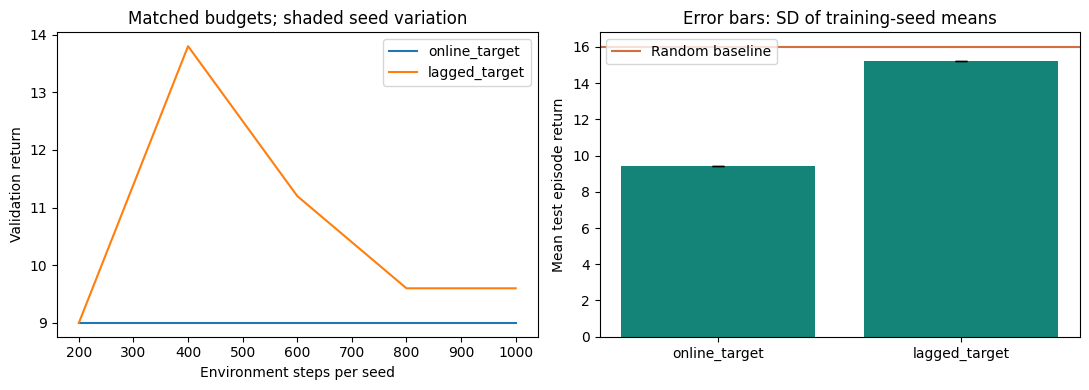

online_target [(11, 9.4, True)]
lagged_target [(11, 15.2, True)]
Seed separation and episode cap: {'train_seeds': [11], 'validation_seeds': [1000, 1001, 1002, 1003, 1004], 'test_seeds': [2000, 2001, 2002, 2003, 2004], 'episode_limit': 500}


In [6]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,result in report["models"].items():
    curves=np.array([[v["validation_mean_return"] for v in r["history"]] for r in result["runs"]])
    steps=[v["environment_steps"] for v in result["runs"][0]["history"]]
    axes[0].plot(steps,curves.mean(0),label=name)
    axes[0].fill_between(steps,curves.mean(0)-curves.std(0),curves.mean(0)+curves.std(0),alpha=.15)
names=list(report["models"])
axes[1].bar(names,[report["models"][n]["mean_of_seed_means"] for n in names],yerr=[report["models"][n]["std_of_seed_means"] or 0 for n in names],color="#138477",capsize=4)
axes[1].axhline(np.mean(report["random_baseline_returns"]),color="#d36d42",label="Random baseline")
axes[0].set(xlabel="Environment steps per seed",ylabel="Validation return",title="Matched budgets; shaded seed variation");axes[0].legend()
axes[1].set(ylabel="Mean test episode return",title="Error bars: SD of training-seed means");axes[1].legend()
fig.tight_layout();fig.savefig(OUTPUT/"results.png",dpi=160);plt.show()
for name,result in report["models"].items():print(name,[(r["seed"],r["test_mean_return"],r["exact_reload"]) for r in result["runs"]])
print("Seed separation and episode cap:",report["manifest"])


## Interpretation and attribution

CartPole is a simple simulated task. Three training seeds and20 test episodes per seed are a bounded study, not general RL robustness or real-world control evidence. The online-target configuration may fail; retain that result.

[Farama Gymnasium CartPole](https://gymnasium.farama.org/environments/classic_control/cart_pole/) and its [time-limit guidance](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/). This is original experiment code prepared with AI assistance from the course's deep Q-learning concepts.

Concepts studied through the [IBM AI Engineering Professional Certificate](https://www.coursera.org/professional-certificates/ai-engineer). Original provider conditions remain applicable. Mechanical execution and reload checks do not replace task-specific or human quality evaluation.